In [1]:
from pathlib import Path
import earthaccess

# Log in with your NASA Earthdata Login account
earthaccess.login()

C:\Users\chris\Anaconda3\envs\ocean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Enter your Earthdata Login username: christiecngo
Enter your Earthdata password: ········


In [6]:
concept_id = "C2036877487-POCLOUD"

# The archived collection begins on July 2, 2012
results = earthaccess.search_data(
    concept_id=concept_id,
    temporal=("2022-05-01", "2022-09-30"),
    count=-1
)

print(f"Granules found: {len(results)}")

# for granule in results:
#     print(granule)

output_dir = Path(r"C:\Users\chris\Documents\MAT 257\Project 2\Data")
output_dir.mkdir(parents=True, exist_ok=True)

files = earthaccess.download(
    results,
    local_path=str(output_dir)
)

print(f"Downloaded {len(files)} files")

Granules found: 154


QUEUEING TASKS | : 100%|██████████| 154/154 [00:00<00:00, 3092.32it/s]
PROCESSING TASKS | : 100%|██████████| 154/154 [01:50<00:00,  1.39it/s]
COLLECTING RESULTS | : 100%|██████████| 154/154 [00:00<00:00, 156891.62it/s]

Downloaded 154 files


In [1]:
from pathlib import Path
import xarray as xr

data_dir = Path(r"C:\Users\chris\Documents\MAT 257\Project 2\Data")
nc_files = sorted(data_dir.glob("*.nc"))

def select_europe(ds):
    # Handle either ascending or descending latitude
    if ds.lat[0] < ds.lat[-1]:
        lat_slice = slice(36, 61)
    else:
        lat_slice = slice(61, 36)

    return ds.sel(
        lat=lat_slice,
        lon=slice(-10, 19)
    )

ds_europe = xr.open_mfdataset(
    nc_files,
    combine="by_coords",
    preprocess=select_europe,
    parallel=True,
    chunks={"time": 100}
)

print(ds_europe)

<xarray.Dataset> Size: 218MB
Dimensions:                  (time: 308, lat: 100, lon: 116)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2022-04-30 ... 2022-10-01
  * lat                      (lat) float32 400B 36.12 36.38 ... 60.62 60.88
  * lon                      (lon) float32 464B -9.875 -9.625 ... 18.62 18.88
Data variables: (12/17)
    sea_surface_temperature  (time, lat, lon) float32 14MB dask.array<chunksize=(2, 100, 116), meta=np.ndarray>
    sst_dtime                (time, lat, lon) float64 29MB dask.array<chunksize=(2, 100, 40), meta=np.ndarray>
    dt_analysis              (time, lat, lon) float32 14MB dask.array<chunksize=(2, 100, 116), meta=np.ndarray>
    sses_bias                (time, lat, lon) float32 14MB dask.array<chunksize=(2, 100, 116), meta=np.ndarray>
    sses_standard_deviation  (time, lat, lon) float32 14MB dask.array<chunksize=(2, 100, 116), meta=np.ndarray>
    diurnal_amplitude        (time, lat, lon) float32 14MB dask.array<chunksize

In [3]:
ds_europe["sst_dtime"].head(10)

<xarray.DataArray 'sst_dtime' (time: 10, lat: 10, lon: 10)> Size: 8kB
dask.array<getitem, shape=(10, 10, 10), dtype=float64, chunksize=(2, 10, 10), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 80B 2022-04-30 2022-05-01 ... 2022-05-05
  * lat      (lat) float32 40B 36.12 36.38 36.62 36.88 ... 37.88 38.12 38.38
  * lon      (lon) float32 40B -9.875 -9.625 -9.375 ... -8.125 -7.875 -7.625
Attributes:
    long_name:      time difference from reference time
    standard_name:  dtime
    units:          second
    valid_min:      0
    valid_max:      10000
    comment:        relative time of SST observations

In [11]:
time_counts = (
    ds_europe["time"]
      .resample(time="1D")
      .count()
)

time_counts.compute()

<xarray.DataArray 'time' (time: 155)> Size: 1kB
array([1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       1])
Coordinates:
  * time     (time) datetime64[ns] 1kB 2022-04-30 2022-05-01 ... 2022-10-01
Attributes:
    long_name:      reference time of sst file
    standard_name:  time
    comment:        useful to help interpret sst_dtime

In [13]:
da = ds_europe["dt_analysis"]

observations_per_day = (
    da.resample(time="1D")
      .count(dim=("time", "lat", "lon"))
)

observations_per_day.compute()

<xarray.DataArray 'dt_analysis' (time: 155)> Size: 1kB
array([2225, 2979, 3113, 3125, 3097, 3578, 2936, 3520, 3047, 2948, 3110,
       3160, 3433, 3235, 3602, 3226, 3172, 3029, 2920, 3059, 3095, 3441,
       3257, 3006, 2964, 2718, 3014, 3168, 3517, 3029, 3375, 3195, 2922,
       3345, 3001, 3450, 3237, 3353, 2972, 3415, 3219, 3086, 3154, 2908,
       3500, 3031, 3427, 3319, 3148, 3003, 2583, 2831, 2900, 3273, 3004,
       2786, 2925, 2722, 3308, 2774, 3312, 2869, 3232, 3016, 3261, 2862,
       2831, 2717, 3033, 3483, 3176, 3512, 3181, 3165, 3173, 2994, 3446,
       3123, 3497, 3442, 3228, 2977, 3018, 3496, 3183, 3347, 2954, 3401,
       3123, 2973, 3381, 3200, 3591, 3122, 3335, 3189, 3205, 3126, 2795,
       3444, 3251, 3448, 3304, 3614, 3236, 3178, 3553, 2983, 3251, 2940,
       3259, 3083, 2898, 3105, 2810, 3169, 2729, 3158, 3252, 3486, 3190,
       3027, 3481, 3080, 3601, 2994, 3243, 2838, 2837, 2683, 2338, 2895,
       2860, 3441, 3167, 3089, 2702, 2751, 2885, 2824, 3294, 3059, 3318,
       3334, 2919, 2657, 2901, 3316, 2782, 2854, 2877, 2748, 2790, 2453,
        919])
Coordinates:
  * time     (time) datetime64[ns] 1kB 2022-04-30 2022-05-01 ... 2022-10-01
Attributes:
    long_name:  deviation from sst reference climatology
    reference:  NCEP/Reynolds SST OI-daily-v2 AVHRR-only
    units:      K
    valid_min:  -127
    valid_max:  127
    comment:    delta SST

In [17]:
import pandas as pd

times = pd.Series(ds_europe.time.values)

print(times.value_counts().head(10))

2022-05-02    2
2022-05-03    2
2022-05-04    2
2022-05-06    2
2022-05-07    2
2022-05-08    2
2022-05-09    2
2022-05-10    2
2022-05-11    2
2022-05-12    2
Name: count, dtype: int64


In [2]:
import matplotlib.pyplot as plt
import numpy as np

sst = ds_europe["sea_surface_temperature"].isel(time=0)

# Make sure latitude is ordered before slicing
europe_sst = sst.sortby("lat")

print(europe_sst.dims)
print(europe_sst.shape)
print(europe_sst.dtype)

('lat', 'lon')
(100, 116)
float32


In [9]:
points = (
    europe_sst
    .stack(point=("lat", "lon"))
    .rename("temperature")
    .to_dataframe()
    .reset_index()
    .dropna(subset=["temperature"])
)

points.head()

,lat,lon,time,temperature
0,36.125,-9.875,2022-04-30,291.750000
1,36.125,-9.625,2022-04-30,291.600006
2,36.125,-9.375,2022-04-30,291.449982
3,36.125,-9.125,2022-04-30,290.850006
4,36.125,-8.875,2022-04-30,290.699982


In [6]:
variables = [
    "sea_surface_temperature",
    "wind_speed",
    "water_vapor"
]

raw_points = (
    ds_europe
    .stack(point=("lat", "lon"))
    .to_dataframe()
    .reset_index()
)

print(raw_points[variables].isna().sum())
print(raw_points[variables].notna().mean() * 100)

sea_surface_temperature    3092644
wind_speed                 2934560
water_vapor                2373446
dtype: int64
sea_surface_temperature    13.439207
wind_speed                 17.863860
water_vapor                33.569021
dtype: float64


In [8]:
len(points)

11600

In [10]:
len(points)

2225

In [11]:
2225/11600

0.19181034482758622

In [5]:
rng = np.random.default_rng(0)

# Select 20% of the data randomly for testing
test_idx = rng.choice(
    points.index,
    size=int(0.20 * len(points)),
    replace=False
)

points["set"] = "train"
points.loc[test_idx, "set"] = "test"

train = points[points["set"] == "train"]
test = points[points["set"] == "test"]

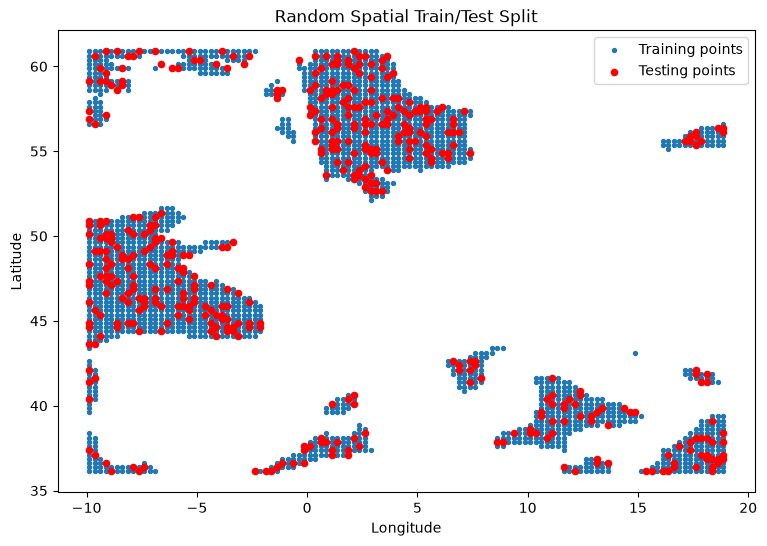

In [6]:
plt.figure(figsize=(9, 6))

plt.scatter(
    train["lon"], train["lat"],
    s=8, label="Training points"
)

plt.scatter(
    test["lon"], test["lat"],
    s=20, color="red", label="Testing points"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Random Spatial Train/Test Split")
plt.legend()
plt.show()

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))

sst_values = europe_sst.values

im = ax.pcolormesh(
    europe_sst.lon.values,
    europe_sst.lat.values,
    sst_values,
    shading="auto",
    cmap="turbo"
)

fig.colorbar(im, ax=ax, label="Temperature (K)")

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Sea-Surface Temperature: 36–61°N, 10°W–19°E")

plt.tight_layout()
plt.savefig("europe_sst.png", dpi=150)
plt.close(fig)

In [10]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, DotProduct, RBF, ExpSineSquared, ConstantKernel, WhiteKernel
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

X_train = train[
    ["lat", "lon"]
]

y_train = train["temperature"]

X_test = test[
    ["lat", "lon"]
]

y_test = test["temperature"]

x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

kernel_specs = {
    "Matern_32": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=1.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "Matern_52": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=2.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "RBF": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * RBF(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2)
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "DotProduct": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * DotProduct(
            sigma_0=1.0,
            sigma_0_bounds=(1e-3, 1e3)
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    )
}


models = {}
predictions = {}
metrics = []

for name, kernel in kernel_specs.items():

    model = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=2,
        random_state=0
    )

    model.fit(X_train_scaled, y_train)

    y_pred, y_std = model.predict(
        X_test_scaled,
        return_std=True
    )

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    models[name] = model

    predictions[name] = {
        "prediction": y_pred,
        "std": y_std
    }

    metrics.append({
        "kernel": name,
        "RMSE": rmse,
        "MAE": mae,
        "log_marginal_likelihood": model.log_marginal_likelihood()
    })

C:\Users\chris\Anaconda3\envs\ocean\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__sigma_0 is close to the specified lower bound 0.001. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [12]:
import pandas as pd
metrics_df = pd.DataFrame(metrics).sort_values("RMSE")

metrics_df

,kernel,RMSE,MAE,log_marginal_likelihood
0,Matern_32,0.296183,0.134538,1771.393881
1,Matern_52,0.307872,0.143967,1669.739946
2,RBF,0.353368,0.174383,1398.593192
3,DotProduct,1.023195,0.742927,-220.817367


In [5]:
import matplotlib.pyplot as plt
import numpy as np

variables = [
    "sea_surface_temperature",
    "wind_speed",
    "water_vapor"
]

europe_data = (
    ds_europe[variables]
    .isel(time=0)
)

# Make sure latitude is ordered before slicing
europe_data = europe_data.sortby("lat")

print(dict(europe_data.sizes))

{'lat': 100, 'lon': 116}


In [6]:
points = (
    europe_data
    .stack(point=("lat", "lon"))
    .to_dataframe()
    .reset_index()
    .dropna(subset=variables)
    .rename(
        columns={
            "sea_surface_temperature": "temperature"
        }
    )
)

points.head()

,lat,lon,temperature,wind_speed,water_vapor,time
0,36.125,-9.875,291.750000,4.400000,16.199997,2022-04-30
1,36.125,-9.625,291.600006,4.400000,14.999998,2022-04-30
2,36.125,-9.375,291.449982,4.199999,14.999998,2022-04-30
3,36.125,-9.125,290.850006,4.400000,14.399998,2022-04-30
4,36.125,-8.875,290.699982,4.799999,13.799997,2022-04-30


In [8]:
rng = np.random.default_rng(0)

# Select 20% of the data randomly for testing
test_idx = rng.choice(
    points.index,
    size=int(0.20 * len(points)),
    replace=False
)

points["set"] = "train"
points.loc[test_idx, "set"] = "test"

train = points[points["set"] == "train"]
test = points[points["set"] == "test"]

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, DotProduct, RBF, ExpSineSquared, ConstantKernel, WhiteKernel
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

X_train = train[
    ["lat", "lon", "water_vapor", "wind_speed"]
]

y_train = train["temperature"]

X_test = test[
    ["lat", "lon", "water_vapor", "wind_speed"]
]

y_test = test["temperature"]

x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

kernel_specs = {
    "Matern_32": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=1.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "Matern_52": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=2.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "RBF": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * RBF(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2)
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    ),

    "DotProduct": (
        ConstantKernel(
            1.0,
            constant_value_bounds=(1e-3, 1e3)
        )
        * DotProduct(
            sigma_0=1.0,
            sigma_0_bounds=(1e-3, 1e3)
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-5, 1e2)
        )
    )
}


models = {}
predictions = {}
metrics = []

for name, kernel in kernel_specs.items():

    model = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=2,
        random_state=0
    )

    model.fit(X_train_scaled, y_train)

    y_pred, y_std = model.predict(
        X_test_scaled,
        return_std=True
    )

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    models[name] = model

    predictions[name] = {
        "prediction": y_pred,
        "std": y_std
    }

    metrics.append({
        "kernel": name,
        "RMSE": rmse,
        "MAE": mae,
        "log_marginal_likelihood": model.log_marginal_likelihood()
    })
    
import pandas as pd
metrics_df = pd.DataFrame(metrics).sort_values("RMSE")

metrics_df

C:\Users\chris\Anaconda3\envs\ocean\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__sigma_0 is close to the specified lower bound 0.001. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,kernel,RMSE,MAE,log_marginal_likelihood
0,Matern_32,0.417342,0.237394,1195.153467
1,Matern_52,0.423831,0.243506,1139.892923
2,RBF,0.456396,0.265367,1039.278939
3,DotProduct,0.980152,0.711465,-156.906590


In [1]:
import sys
import os

print("Python executable:", sys.executable)
print("Python prefix:", sys.prefix)
print("Base prefix:", sys.base_prefix)
print("Conda environment:", os.environ.get("CONDA_DEFAULT_ENV"))

Python executable: C:\Users\chris\Anaconda3\envs\ocean\python.exe
Python prefix: C:\Users\chris\Anaconda3\envs\ocean
Base prefix: C:\Users\chris\Anaconda3\envs\ocean
Conda environment: None
